In [1]:
import pandas as pd
import numpy as np
import re
from gensim.models import Word2Vec

In [2]:
data = pd.read_csv("twitter_dataset.csv")

print(data.head())
print(data.shape)
print(data.columns)

   Tweet_ID        Username  \
0         1         julie81   
1         2   richardhester   
2         3  williamsjoseph   
3         4     danielsmary   
4         5      carlwarren   

                                                Text  Retweets  Likes  \
0  Party least receive say or single. Prevent pre...         2     25   
1  Hotel still Congress may member staff. Media d...        35     29   
2  Nice be her debate industry that year. Film wh...        51     25   
3  Laugh explain situation career occur serious. ...        37     18   
4  Involve sense former often approach government...        27     80   

             Timestamp  
0  2023-01-30 11:00:51  
1  2023-01-02 22:45:58  
2  2023-01-18 11:25:19  
3  2023-04-10 22:06:29  
4  2023-01-24 07:12:21  
(10000, 6)
Index(['Tweet_ID', 'Username', 'Text', 'Retweets', 'Likes', 'Timestamp'], dtype='object')


In [4]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'@\w+', '', text)
    text = re.sub(r'#', '', text)
    text = re.sub(r'[^a-z\s]', '', text)

    return text.split()


data['tokens'] = data['Text'].apply(clean_text)

print(data['tokens'].head())

0    [party, least, receive, say, or, single, preve...
1    [hotel, still, congress, may, member, staff, m...
2    [nice, be, her, debate, industry, that, year, ...
3    [laugh, explain, situation, career, occur, ser...
4    [involve, sense, former, often, approach, gove...
Name: tokens, dtype: object


In [5]:
sentences = data['tokens'].tolist()

print("Total tweets:", len(sentences))
print(sentences[:5])

Total tweets: 10000
[['party', 'least', 'receive', 'say', 'or', 'single', 'prevent', 'prevent', 'husband', 'affect', 'may', 'himself', 'cup', 'style', 'evening', 'protect', 'effect', 'another', 'themselves', 'stage', 'perform', 'possible', 'try', 'tax', 'share', 'style', 'television', 'with', 'successful', 'much', 'sell', 'development', 'economy', 'effect'], ['hotel', 'still', 'congress', 'may', 'member', 'staff', 'media', 'draw', 'buy', 'fly', 'identify', 'on', 'another', 'turn', 'minute', 'would', 'local', 'subject', 'way', 'believe', 'which', 'question', 'some', 'message', 'own', 'all', 'imagine', 'join', 'agency', 'indicate'], ['nice', 'be', 'her', 'debate', 'industry', 'that', 'year', 'film', 'where', 'generation', 'push', 'discover', 'partner', 'level', 'nearly', 'money', 'store', 'style', 'may', 'enjoy', 'kid', 'discuss', 'blue', 'save', 'model', 'another', 'about', 'along', 'everybody', 'especially', 'dinner', 'character', 'yard'], ['laugh', 'explain', 'situation', 'career', 'o

In [6]:
model = Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=2,
    sg=0,
    workers=4,
    epochs=10
)

print("Vocabulary Size:", len(model.wv))

Vocabulary Size: 971


In [7]:
word = "good"

if word in model.wv:
    print("Embedding of", word)
    print(model.wv[word])
else:
    print("Word not found in vocabulary")

Embedding of good
[-0.15800197  0.20783132  0.09647461  0.01540364  0.06778234 -0.20524369
 -0.08015115  0.23323058 -0.00222021  0.10494743 -0.27394986 -0.25540996
 -0.05012456  0.05150466  0.06041397  0.00381555 -0.03310971 -0.08388329
  0.04780376 -0.14210346  0.11360463  0.04509848 -0.0154865   0.005722
 -0.0835243   0.05839383 -0.11103833 -0.15602057  0.03901532 -0.03838999
  0.1763719  -0.02468005 -0.13786098  0.17682551 -0.09157055  0.0524052
 -0.09367334 -0.21024081 -0.16233115 -0.23866068 -0.01788232  0.00422487
  0.11154206 -0.04792684 -0.03013551 -0.00378991 -0.10493116  0.09203362
  0.05449882  0.12592575  0.02253236 -0.14684644 -0.08758911  0.03594008
 -0.2764516   0.14623065  0.11334503  0.00753589 -0.22619829 -0.10568705
  0.10007757  0.18114483 -0.24262062 -0.10204947 -0.14607728  0.01004347
  0.02062924  0.03247299 -0.04931953  0.05142328 -0.06352927 -0.09042206
  0.22804059 -0.09335448  0.07696847  0.08331618 -0.07816902 -0.05299612
 -0.16868603  0.09068265 -0.05834099

In [8]:
word = "good"

if word in model.wv:
    print(model.wv.most_similar(word, topn=5))
else:
    print("Word not found in vocabulary")

[('campaign', 0.9772859215736389), ('seat', 0.9762065410614014), ('television', 0.975101888179779), ('player', 0.9747301936149597), ('identify', 0.9744054675102234)]


In [9]:
word1 = "good"
word2 = "great"

if word1 in model.wv and word2 in model.wv:
    similarity = model.wv.similarity(word1, word2)
    print("Similarity:", similarity)
else:
    print("One or both words are not in vocabulary")

Similarity: 0.9637557


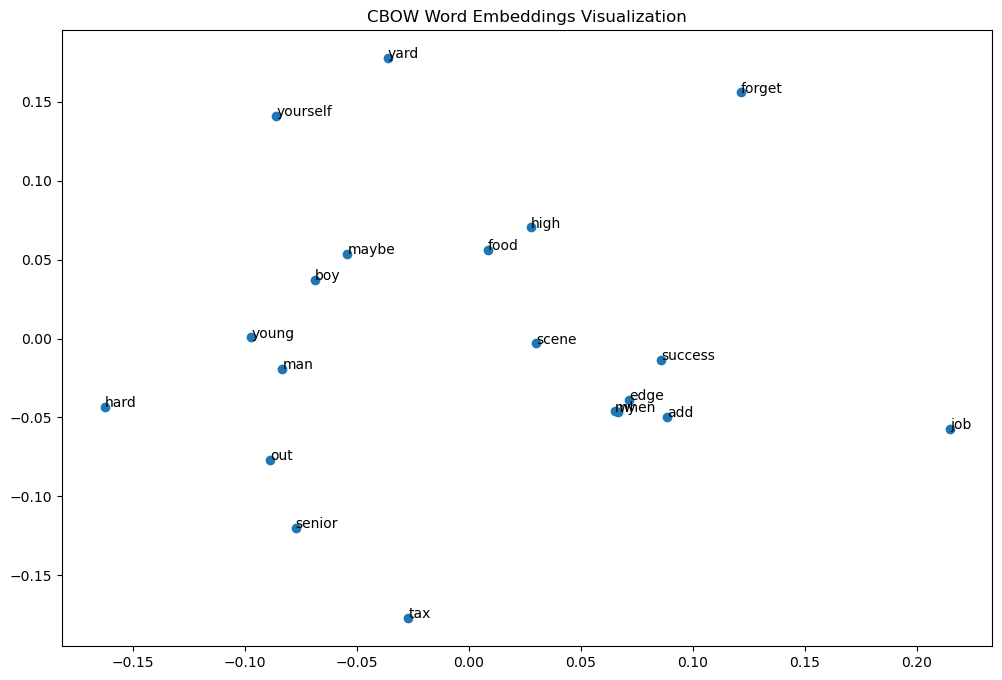

In [10]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

words = list(model.wv.index_to_key[:20])

vectors = [model.wv[word] for word in words]

pca = PCA(n_components=2)
result = pca.fit_transform(vectors)

plt.figure(figsize=(12, 8))

plt.scatter(result[:, 0], result[:, 1])

for i, word in enumerate(words):
    plt.annotate(word, (result[i, 0], result[i, 1]))

plt.title("CBOW Word Embeddings Visualization")
plt.show()